# Fase 3 — Primera comparación de modelos de precios

**Objetivo:** estimar el precio anunciado de un alojamiento con características conocidas, utilizando el corte de Río de Janeiro. No se estima precio óptimo, ocupación, ingresos ni rentabilidad.

## Decisiones a partir del EDA

- Mantener todos los precios positivos disponibles (44 147 en el corte recibido), incluidos los extremos. Los 4 100 anuncios sin precio no se usan como ejemplos supervisados, pero se conservan para oferta e inferencia.
- Usar características físicas, geografía, tipo y atributos del anfitrión. Excluir IDs como predictores, precio y sus derivados, cotizaciones, ingresos estimados, disponibilidad y reseñas de esta primera especificación.
- Comparar una referencia de mediana, Ridge con precio transformado y Random Forest con precio transformado. `log1p` reduce la escala del objetivo, pero no demuestra que los extremos sean errores ni elimina su influencia en las métricas monetarias.
- Separar entrenamiento, validación y prueba **por anfitrión**. Se mide generalización a anfitriones reservados dentro del mismo corte, no a fechas futuras. La selección se hace por MAE de validación. La prueba se usa al final, después de elegir el modelo.

El EDA anterior ya exploró el corte completo. Esta reserva de prueba evita ajustar los modelos con sus filas, pero no es una validación externa totalmente independiente de las decisiones del proyecto. Una comprobación más fuerte requeriría otro corte no explorado.

## Ejecución

Guarda este archivo en `notebooks/`, selecciona tu `.venv` y ejecuta las **10 celdas** en orden. Solo lee `clean.listings`: no escribe en PostgreSQL. Usa las librerías que ya instalaste; joblib es dependencia de scikit-learn. La parte de entrenamiento puede tardar varios minutos.

Se guardan resultados en `reports/modelado/` y el modelo en `models/`. Repetir las celdas finales reemplaza estos archivos. La configuración inicial limita el bosque a 120 árboles y 2 procesos para moderar el uso de recursos.

## 1. Preparar entorno y configuración

MAE y RMSE se reportan en BRL. El MAE mide el error absoluto promedio; RMSE penaliza más los errores grandes. R² puede ser negativo si el modelo funciona peor que la referencia matemática de esa métrica. No se exige obtener un resultado positivo para considerar válida la ejecución.

In [1]:
import sys
import json
import time
from pathlib import Path
from datetime import datetime, timezone
from getpass import getpass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import joblib
from sklearn.base import clone
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, median_absolute_error, r2_score
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from IPython.display import display

HOST, PORT = 'localhost', 5432
DATABASE, USER = 'proy_airbnb_rio', 'postgres'
RAIZ_MANUAL = ''
SEMILLA = 42
ARBOLES = 120
PROCESOS = 2
SUELO_PREDICCION_BRL = 0.01  # Regla fija de dominio; no se aprende de los precios de prueba.
if RAIZ_MANUAL:
    RAIZ = Path(RAIZ_MANUAL).expanduser().resolve()
else:
    inicio = Path.cwd().resolve()
    RAIZ = next((p for p in [inicio, *inicio.parents]
                 if (p/'data'/'raw').is_dir() and (p/'src').is_dir()), None)
if RAIZ is None:
    raise RuntimeError('Configura RAIZ_MANUAL con la carpeta principal del proyecto.')
REPORTES = RAIZ/'reports'/'modelado'
MODELOS = RAIZ/'models'
FIGURAS = REPORTES/'figuras'
for p in [REPORTES, MODELOS, FIGURAS]:p.mkdir(parents=True,exist_ok=True)
print('Python:',sys.executable)
print('scikit-learn:',sklearn.__version__)
print('Resultados:',REPORTES)

Python: c:\Users\user\Documents\Inteligencia de negocios\Proyecto_IN\Proy_Analysis_Airbnb_Business_Model\.venv\Scripts\python.exe
scikit-learn: 1.9.1
Resultados: C:\Users\user\Documents\Inteligencia de negocios\Proyecto_IN\Proy_Analysis_Airbnb_Business_Model\reports\modelado


## 2. Leer la capa limpia y construir la matriz de características

Las ausencias numéricas siguen como NaN; se imputarán dentro de cada pipeline, aprendiendo únicamente de su entrenamiento. Las categorías desconocidas usan una etiqueta fija. Los IDs solo se utilizan para agrupar, comprobar y vincular resultados.

Los atributos de anfitrión corresponden a su estado observado en este corte. Si luego se pretende estimar para un anfitrión nuevo sin esos datos, habrá que revisar ese escenario de uso.

In [2]:
motor=create_engine(URL.create('postgresql+psycopg2',username=USER,
    password=getpass(f'Contraseña de {USER}: '),host=HOST,port=PORT,database=DATABASE),
    connect_args={'connect_timeout':10})
try:
    with motor.connect() as conexion:
        with conexion.begin():
            conexion.execute(text('SET TRANSACTION READ ONLY'))
            df=pd.read_sql_query(text('SELECT * FROM clean.listings'),conexion)
finally:
    motor.dispose()

NUMERICAS=['latitude','longitude','accommodates','bedrooms','beds','bathrooms_derived']
CATEGORICAS=['neighbourhood_cleansed','room_type','property_type',
             'bathroom_shared','host_is_superhost','host_identity_verified']
FEATURES=NUMERICAS+CATEGORICAS
requeridas=set(FEATURES+['id','host_id','price','price_currency'])
if not requeridas<=set(df.columns):
    raise ValueError(f'Faltan columnas: {sorted(requeridas-set(df.columns))}')
if df.empty or df['id'].isna().any() or df['id'].duplicated().any():
    raise ValueError('Tabla vacía o con IDs ausentes/repetidos.')
if set(df['price_currency'].dropna().astype(str))!={'BRL'} or df['price_currency'].isna().any():
    raise ValueError('Comprobar moneda antes de entrenar.')
df=df.reset_index(drop=True)
ids=df['id'].astype(str)
y_total=pd.to_numeric(df['price'],errors='coerce').astype(float)
con_precio=y_total.gt(0)&np.isfinite(y_total)
X_total=pd.DataFrame(index=df.index)
for c in NUMERICAS:
    X_total[c]=pd.to_numeric(df[c],errors='coerce').astype(float).replace([np.inf,-np.inf],np.nan)
for c in CATEGORICAS:
    X_total[c]=df[c].astype('string').str.strip().replace('',pd.NA).fillna('<SIN DATO>').astype(str)
datos_modelo=df.loc[con_precio,['id','host_id']].reset_index(drop=True)
datos_modelo['id']=datos_modelo['id'].astype(str)
X=X_total.loc[con_precio,FEATURES].reset_index(drop=True)
y=y_total.loc[con_precio].reset_index(drop=True)
grupos=datos_modelo['host_id'].astype('string').str.strip()
sin_host=grupos.isna()|grupos.eq('').fillna(False)
grupos=grupos.mask(sin_host,'<HOST_AUSENTE>_'+datos_modelo['id'].astype(str)).astype(str)
if len(y)<100 or grupos.nunique()<10:
    raise ValueError('Hay pocos datos o grupos para esta configuración de evaluación.')
print('Anuncios para supervisión:',len(y))
print('Anuncios sin precio excluidos de supervisión:',int((~con_precio).sum()))
print('Grupos anfitrión disponibles:',grupos.nunique())
print('Variables:',FEATURES)

Anuncios para supervisión: 44147
Anuncios sin precio excluidos de supervisión: 4100
Grupos anfitrión disponibles: 24721
Variables: ['latitude', 'longitude', 'accommodates', 'bedrooms', 'beds', 'bathrooms_derived', 'neighbourhood_cleansed', 'room_type', 'property_type', 'bathroom_shared', 'host_is_superhost', 'host_identity_verified']


## 3. Separar por anfitrión y registrar las particiones

Primero se reserva el 20 % de grupos para prueba. Del 80 % restante se reserva otro 20 % para validación. Son proporciones de **anfitriones**, por lo que las cantidades de anuncios no tienen por qué ser exactamente 64/16/20.

No se usa el objetivo para estratificar ni se eliminan extremos. La partición es reproducible para los mismos registros ordenados; se ordenan primero los IDs para no depender del orden de PostgreSQL.

In [3]:
orden=np.argsort(datos_modelo['id'].astype(str).to_numpy(),kind='stable')
datos_modelo=datos_modelo.iloc[orden].reset_index(drop=True)
X=X.iloc[orden].reset_index(drop=True)
y=y.iloc[orden].reset_index(drop=True)
grupos=grupos.iloc[orden].reset_index(drop=True)
separador=GroupShuffleSplit(n_splits=1,test_size=.20,random_state=SEMILLA)
idx_desarrollo,idx_prueba=next(separador.split(X,y,groups=grupos))
separador_val=GroupShuffleSplit(n_splits=1,test_size=.20,random_state=SEMILLA+1)
a,b=next(separador_val.split(X.iloc[idx_desarrollo],y.iloc[idx_desarrollo],groups=grupos.iloc[idx_desarrollo]))
idx_entrenamiento=idx_desarrollo[a]
idx_validacion=idx_desarrollo[b]
indices={'entrenamiento':idx_entrenamiento,'validacion':idx_validacion,'prueba':idx_prueba}
conjuntos={k:set(grupos.iloc[v]) for k,v in indices.items()}
for a,b in [('entrenamiento','validacion'),('entrenamiento','prueba'),('validacion','prueba')]:
    if conjuntos[a]&conjuntos[b]:raise RuntimeError('Se detectó un anfitrión en dos particiones.')
if len(set(np.concatenate(list(indices.values()))))!=len(y):
    raise RuntimeError('Las particiones no cubren los registros exactamente una vez.')
particiones=datos_modelo.copy()
particiones['particion']=''
filas=[]
for nombre,idx in indices.items():
    particiones.loc[idx,'particion']=nombre
    filas.append({'particion':nombre,'anuncios':len(idx),'grupos_anfitrion':len(conjuntos[nombre])})
resumen_particiones=pd.DataFrame(filas)
particiones.to_csv(REPORTES/'particiones_modelo.csv',index=False,encoding='utf-8-sig')
display(resumen_particiones)
print('Anfitriones compartidos entre particiones: 0')

,particion,anuncios,grupos_anfitrion
0,entrenamiento,27834,15820
1,validacion,7107,3956
2,prueba,9206,4945


Anfitriones compartidos entre particiones: 0


## 4. Construir pipelines y candidatos

Las medianas de imputación, las escalas y las categorías se aprenden cuando se llama a `fit`, usando únicamente las filas de entrenamiento correspondientes. Los modelos logarítmicos se vuelven a la escala monetaria con `expm1` antes de evaluar. Esa inversión no se interpreta automáticamente como una estimación insesgada de la media del precio.

Las configuraciones se fijan antes de evaluar. Esta es una comparación inicial, no una búsqueda exhaustiva de hiperparámetros.

In [4]:
def preprocesamiento(escalar):
    pasos=[('imputar',SimpleImputer(strategy='median',add_indicator=True,keep_empty_features=True))]
    if escalar:pasos.append(('escalar',StandardScaler()))
    return ColumnTransformer([
        ('numericas',Pipeline(pasos),NUMERICAS),
        ('categoricas',OneHotEncoder(handle_unknown='ignore',min_frequency=10,sparse_output=True),CATEGORICAS),
    ],remainder='drop',sparse_threshold=1.0)

candidatos={
    'Referencia_mediana':Pipeline([
        ('preparar',preprocesamiento(False)),('regresor',DummyRegressor(strategy='median'))]),
    'Ridge_log':TransformedTargetRegressor(
        regressor=Pipeline([('preparar',preprocesamiento(True)),
                            ('regresor',Ridge(alpha=10.0,solver='lsqr'))]),
        func=np.log1p,inverse_func=np.expm1),
    'RandomForest_log':TransformedTargetRegressor(
        regressor=Pipeline([('preparar',preprocesamiento(False)),
            ('regresor',RandomForestRegressor(n_estimators=ARBOLES,max_depth=18,
                min_samples_leaf=5,max_features=.8,random_state=SEMILLA,n_jobs=PROCESOS))]),
        func=np.log1p,inverse_func=np.expm1),
}

def predecir(modelo,matriz):
    p=np.asarray(modelo.predict(matriz),dtype=float).reshape(-1)
    if not np.isfinite(p).all():raise ValueError('El modelo produjo predicciones no finitas.')
    return np.maximum(SUELO_PREDICCION_BRL,p)

def metricas_precio(real,estimado):
    real=np.asarray(real,dtype=float)
    estimado=np.asarray(estimado,dtype=float)
    return {'MAE_BRL':float(mean_absolute_error(real,estimado)),
            'RMSE_BRL':float(np.sqrt(mean_squared_error(real,estimado))),
            'MedAE_BRL':float(median_absolute_error(real,estimado)),
            'R2':float(r2_score(real,estimado)) if len(real)>1 and np.var(real)>0 else None}

print('Candidatos:',list(candidatos))

Candidatos: ['Referencia_mediana', 'Ridge_log', 'RandomForest_log']


## 5. Entrenar y elegir por MAE de validación

La referencia también puede ganar. No se dará por hecho que un modelo complejo mejora el resultado. Esta celda no evalúa prueba. No cambies configuraciones repetidamente a partir de las métricas de prueba de la celda 8.

In [5]:
modelos_ajustados={}
filas_metricas=[]
for nombre,definicion in candidatos.items():
    inicio=time.perf_counter()
    modelo=clone(definicion)
    modelo.fit(X.iloc[idx_entrenamiento],y.iloc[idx_entrenamiento])
    p=predecir(modelo,X.iloc[idx_validacion])
    fila={'modelo':nombre,**metricas_precio(y.iloc[idx_validacion],p),
          'segundos':time.perf_counter()-inicio}
    filas_metricas.append(fila)
    modelos_ajustados[nombre]=modelo
    print(f"{nombre}: MAE validación = BRL {fila['MAE_BRL']:,.2f}")
comparacion=pd.DataFrame(filas_metricas).sort_values(['MAE_BRL','modelo']).reset_index(drop=True)
nombre_elegido=str(comparacion.iloc[0]['modelo'])
elegido_validacion=modelos_ajustados[nombre_elegido]
comparacion.to_csv(REPORTES/'comparacion_validacion.csv',index=False,encoding='utf-8-sig')
display(comparacion.round(3))
print('Modelo elegido por validación:',nombre_elegido)

Referencia_mediana: MAE validación = BRL 562.75
Ridge_log: MAE validación = BRL 457.13
RandomForest_log: MAE validación = BRL 404.82


,modelo,MAE_BRL,RMSE_BRL,MedAE_BRL,R2,segundos
0,RandomForest_log,404.820,1665.493,127.743,0.335,47.532
1,Ridge_log,457.130,2134.446,140.361,-0.092,0.339
2,Referencia_mediana,562.747,2084.185,188.000,-0.041,0.260


Modelo elegido por validación: RandomForest_log


## 6. Interpretación exploratoria en validación

La importancia por permutación mide cuánto empeora el MAE al desordenar una variable. No demuestra causalidad; las variables correlacionadas, como barrio y coordenadas, pueden repartirse importancia. Se calcula sobre una muestra de validación y el modelo elegido aún no reajustado con esa muestra. La misma validación se usó para seleccionar modelo, por lo que esta interpretación es exploratoria.

,variable,aumento_MAE_BRL,desviacion_repeticiones
5,bathrooms_derived,81.15,5.90
3,bedrooms,66.71,6.42
0,latitude,65.71,2.67
1,longitude,56.51,1.75
2,accommodates,18.85,0.26
10,host_is_superhost,9.41,1.40
7,room_type,7.87,2.37
4,beds,7.13,1.30
6,neighbourhood_cleansed,6.84,0.60
9,bathroom_shared,2.88,0.12


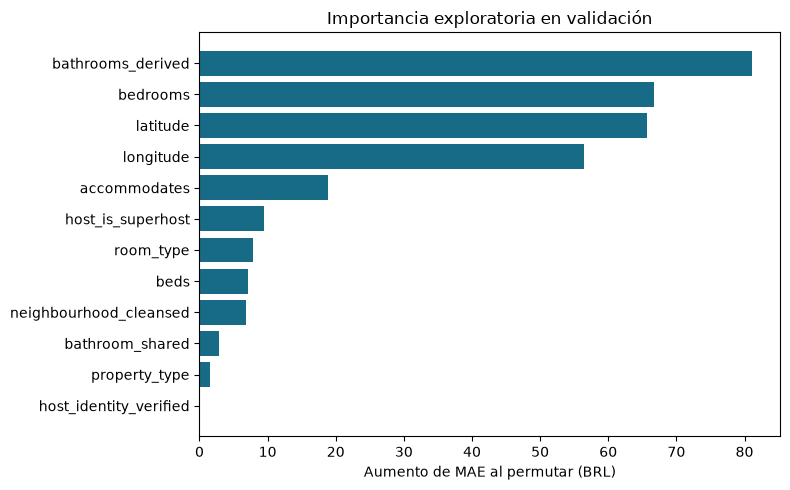

In [6]:
rng=np.random.default_rng(SEMILLA)
idx_importancia=np.sort(rng.choice(idx_validacion,size=min(1500,len(idx_validacion)),replace=False))
def puntuacion_mae(est,matriz,real):
    return -mean_absolute_error(real,predecir(est,matriz))
permutacion=permutation_importance(elegido_validacion,X.iloc[idx_importancia],y.iloc[idx_importancia],
    scoring=puntuacion_mae,n_repeats=3,random_state=SEMILLA,n_jobs=1)
importancias=pd.DataFrame({'variable':FEATURES,'aumento_MAE_BRL':permutacion.importances_mean,
                          'desviacion_repeticiones':permutacion.importances_std}).sort_values('aumento_MAE_BRL',ascending=False)
importancias.to_csv(REPORTES/'importancia_variables.csv',index=False,encoding='utf-8-sig')
display(importancias.round(2))
fig,ax=plt.subplots(figsize=(8,5))
v=importancias.sort_values('aumento_MAE_BRL')
ax.barh(v['variable'],v['aumento_MAE_BRL'],color='#176B87')
ax.set(xlabel='Aumento de MAE al permutar (BRL)',title='Importancia exploratoria en validación')
fig.tight_layout();fig.savefig(FIGURAS/'01_importancia_variables.png',dpi=180,bbox_inches='tight')
plt.show();plt.close(fig)

## 7. Reajustar el modelo seleccionado con desarrollo

Solo después de elegirlo, se ajusta una copia con entrenamiento + validación. La prueba sigue reservada. Se reajusta la referencia con las mismas filas para que su comparación sea coherente. Se conserva esta versión del modelo, sin reajustarla posteriormente con prueba.

In [7]:
modelo_final=clone(candidatos[nombre_elegido])
modelo_final.fit(X.iloc[idx_desarrollo],y.iloc[idx_desarrollo])
if nombre_elegido=='Referencia_mediana':
    referencia_final=modelo_final
else:
    referencia_final=clone(candidatos['Referencia_mediana'])
    referencia_final.fit(X.iloc[idx_desarrollo],y.iloc[idx_desarrollo])
umbral_sensibilidad=float(y.iloc[idx_desarrollo].quantile(.99))
print('Ajuste final con anuncios de desarrollo:',len(idx_desarrollo))
print('Umbral de sensibilidad calculado solo con desarrollo (P99):',round(umbral_sensibilidad,2))

Ajuste final con anuncios de desarrollo: 34941
Umbral de sensibilidad calculado solo con desarrollo (P99): 7289.73


## 8. Evaluar una vez en prueba

La evaluación principal incluye todos los precios positivos de prueba, también los extremos. Se añade una comparación de sensibilidad hasta el P99 de **desarrollo**, sin cambiar el modelo ni el conjunto principal. No es correcto sustituir el resultado completo por ese subconjunto porque resulte más favorable.

Un R² bajo o negativo, o una mejora pequeña frente a la mediana, se reporta tal como salga. No garantiza capacidad para recomendar precios competitivos.

,papel,modelo,poblacion,MAE_BRL,RMSE_BRL,MedAE_BRL,R2
0,elegido,RandomForest_log,Prueba completa,594.060,8757.652,128.196,0.015
1,referencia,Referencia_mediana,Prueba completa,758.794,8845.173,190.000,-0.005


,modelo,anuncios,poblacion,MAE_BRL,RMSE_BRL,MedAE_BRL,R2
0,RandomForest_log,9098,Hasta P99 de desarrollo; sensibilidad,297.944,671.952,126.043,0.357
1,Referencia_mediana,9098,Hasta P99 de desarrollo; sensibilidad,411.365,875.240,187.000,-0.090


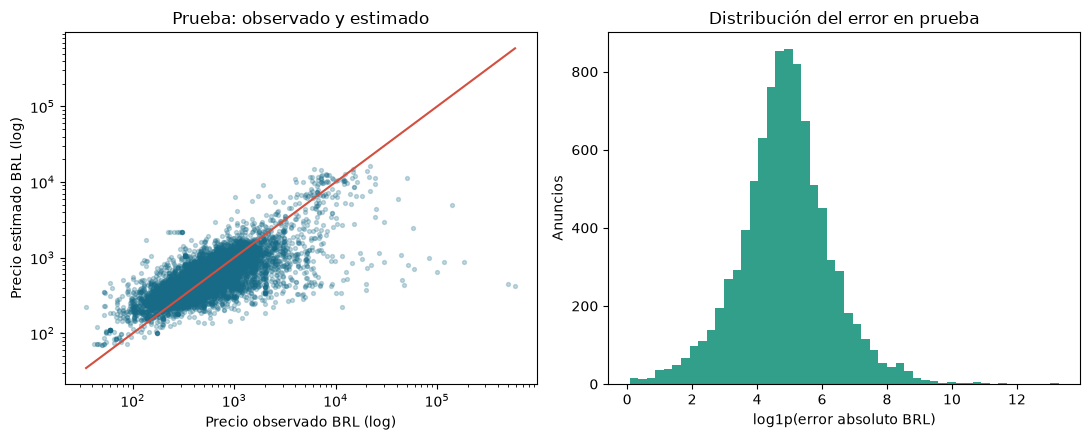

In [8]:
p_prueba=predecir(modelo_final,X.iloc[idx_prueba])
p_referencia=predecir(referencia_final,X.iloc[idx_prueba])
real_prueba=y.iloc[idx_prueba].to_numpy()
resultados_prueba=pd.DataFrame([
    {'papel':'elegido','modelo':nombre_elegido,'poblacion':'Prueba completa',**metricas_precio(real_prueba,p_prueba)},
    {'papel':'referencia','modelo':'Referencia_mediana','poblacion':'Prueba completa',**metricas_precio(real_prueba,p_referencia)},
])
central=real_prueba<=umbral_sensibilidad
sensibilidad_prueba=[]
if central.any():
    for nombre,p in [(nombre_elegido,p_prueba),('Referencia_mediana',p_referencia)]:
        sensibilidad_prueba.append({'modelo':nombre,'anuncios':int(central.sum()),
            'poblacion':'Hasta P99 de desarrollo; sensibilidad',**metricas_precio(real_prueba[central],p[central])})
sensibilidad_prueba=pd.DataFrame(sensibilidad_prueba)
resultados_prueba.to_csv(REPORTES/'metricas_prueba.csv',index=False,encoding='utf-8-sig')
sensibilidad_prueba.to_csv(REPORTES/'sensibilidad_prueba.csv',index=False,encoding='utf-8-sig')
display(resultados_prueba.round(3));display(sensibilidad_prueba.round(3))
metricas_modelo=metricas_precio(real_prueba,p_prueba)
metricas_referencia=metricas_precio(real_prueba,p_referencia)
mejora_mae=(100*(metricas_referencia['MAE_BRL']-metricas_modelo['MAE_BRL'])/metricas_referencia['MAE_BRL']
            if metricas_referencia['MAE_BRL']>0 else None)

predicciones_prueba=datos_modelo.iloc[idx_prueba].copy()
predicciones_prueba['precio_observado_BRL']=real_prueba
predicciones_prueba['precio_estimado_BRL']=p_prueba
predicciones_prueba['error_absoluto_BRL']=np.abs(real_prueba-p_prueba)
predicciones_prueba.to_csv(REPORTES/'predicciones_prueba.csv',index=False,encoding='utf-8-sig')
fig,ejes=plt.subplots(1,2,figsize=(11,4.5))
ejes[0].scatter(real_prueba,p_prueba,s=8,alpha=.25,color='#176B87')
limites=[min(real_prueba.min(),p_prueba.min()),max(real_prueba.max(),p_prueba.max())]
ejes[0].plot(limites,limites,color='#D34F3F')
ejes[0].set(xscale='log',yscale='log',xlabel='Precio observado BRL (log)',ylabel='Precio estimado BRL (log)',title='Prueba: observado y estimado')
ejes[1].hist(np.log1p(np.abs(real_prueba-p_prueba)),bins=50,color='#329F8A')
ejes[1].set(xlabel='log1p(error absoluto BRL)',ylabel='Anuncios',title='Distribución del error en prueba')
fig.tight_layout();fig.savefig(FIGURAS/'02_evaluacion_prueba.png',dpi=180,bbox_inches='tight')
plt.show();plt.close(fig)

## 9. Generar estimaciones vinculables a Power BI

Se estima para toda la oferta. Se distingue desarrollo (incluido en ajuste), prueba (reservada) y anuncios sin precio observado. Una estimación de desarrollo no es evidencia de generalización; los anuncios sin precio no tienen un error verificable.

El número de comparables se calcula solo con los anuncios de desarrollo que tienen precio: mismo barrio, tipo y grupo de capacidad. Menos de 30 se marca como soporte bajo; no es un intervalo de confianza ni una probabilidad de acierto. La diferencia entre precio publicado y estimado no demuestra sobreprecio o infravaloración.

In [9]:
p_todos=predecir(modelo_final,X_total[FEATURES])
particion_por_id=particiones.set_index('id')['particion']
salida=pd.DataFrame({'id':ids,'precio_observado_BRL':y_total,'precio_estimado_BRL':p_todos})
salida['particion_original']=salida['id'].map(particion_por_id).fillna('sin_precio')
salida['incluido_en_ajuste_final']=salida['particion_original'].isin(['entrenamiento','validacion'])
salida['diferencia_publicado_menos_estimado_BRL']=salida['precio_observado_BRL']-salida['precio_estimado_BRL']
salida['diferencia_pct_vs_estimado']=100*salida['diferencia_publicado_menos_estimado_BRL']/salida['precio_estimado_BRL']
contexto=pd.DataFrame({
    'id':ids,
    'neighbourhood_cleansed':X_total['neighbourhood_cleansed'],
    'room_type':X_total['room_type'],
    'grupo_capacidad':pd.cut(X_total['accommodates'],bins=[0,2,4,6,8,np.inf],
          labels=['1-2','3-4','5-6','7-8','9+']).astype('string').fillna('<SIN DATO>'),
})
claves=['neighbourhood_cleansed','room_type','grupo_capacidad']
ids_desarrollo=set(datos_modelo.iloc[idx_desarrollo]['id'].astype(str))
soporte=contexto.loc[contexto['id'].isin(ids_desarrollo)].groupby(claves,observed=True,dropna=False).size().reset_index(name='comparables_desarrollo')
contexto=contexto.merge(soporte,on=claves,how='left',validate='many_to_one')
contexto['comparables_desarrollo']=contexto['comparables_desarrollo'].fillna(0).astype(int)
contexto['soporte_bajo_segmento']=contexto['comparables_desarrollo'].lt(30)
salida=salida.merge(contexto,on='id',how='left',validate='one_to_one')
if len(salida)!=len(df) or salida['id'].duplicated().any():
    raise RuntimeError('La exportación no conserva todos los IDs una sola vez.')
if salida['particion_original'].eq('sin_precio').sum()!=int((~con_precio).sum()):
    raise RuntimeError('No se pudieron vincular correctamente las particiones con los IDs.')
salida['modelo']=nombre_elegido
salida.to_csv(REPORTES/'estimaciones_para_powerbi.csv',index=False,encoding='utf-8-sig')
display(salida.head())
print('Estimaciones exportadas:',len(salida))

,id,precio_observado_BRL,precio_estimado_BRL,particion_original,incluido_en_ajuste_final,diferencia_publicado_menos_estimado_BRL,diferencia_pct_vs_estimado,neighbourhood_cleansed,room_type,grupo_capacidad,comparables_desarrollo,soporte_bajo_segmento,modelo
0,17878,513.00,624.745924,entrenamiento,True,-111.745924,-17.886619,Copacabana,Entire home/apt,5-6,2009,False,RandomForest_log
1,25026,422.00,418.050842,entrenamiento,True,3.949158,0.944660,Copacabana,Entire home/apt,3-4,4911,False,RandomForest_log
2,35764,366.00,440.706124,entrenamiento,True,-74.706124,-16.951460,Copacabana,Entire home/apt,1-2,1700,False,RandomForest_log
3,48305,3761.43,6078.063764,entrenamiento,True,-2316.633764,-38.114667,Ipanema,Entire home/apt,9+,41,False,RandomForest_log
4,48901,1173.25,1657.979841,entrenamiento,True,-484.729841,-29.236172,Copacabana,Entire home/apt,9+,249,False,RandomForest_log


Estimaciones exportadas: 48247


## 10. Guardar modelo, metadatos y resumen

Se guarda un paquete joblib con el estimador, las variables y el suelo monetario. Para inferencia hay que preparar las mismas columnas como en la celda 2 y aplicar `np.maximum(paquete['suelo_prediccion_BRL'], paquete['estimador'].predict(X_nuevo))`. El paquete no almacena contraseña ni conexión a PostgreSQL.

El estimador se conserva entrenado en desarrollo; prueba no se incorpora después del informe. Los archivos joblib requieren un entorno compatible con las versiones registradas.

In [10]:
metadatos={
    'generado_utc':datetime.now(timezone.utc).isoformat(),
    'origen':'clean.listings','moneda':'BRL','modelo_elegido':nombre_elegido,
    'criterio_seleccion':'Menor MAE en validación; grupos de anfitrión disjuntos',
    'anuncios_totales':len(df),'anuncios_supervisados':len(y),
    'anuncios_sin_precio_supervisado':int((~con_precio).sum()),
    'variables_numericas':NUMERICAS,'variables_categoricas':CATEGORICAS,
    'particiones':resumen_particiones.to_dict(orient='records'),
    'anfitriones_compartidos_entre_particiones':0,
    'metricas_prueba_modelo':metricas_modelo,
    'metricas_prueba_referencia':metricas_referencia,
    'mejora_MAE_vs_referencia_pct':mejora_mae,
    'umbral_P99_desarrollo_BRL':umbral_sensibilidad,
    'filas_prueba_sensibilidad':int(central.sum()),
    'estimaciones_exportadas':len(salida),
    'suelo_prediccion_BRL':SUELO_PREDICCION_BRL,
    'extremos_eliminados_por_percentil':0,
    'filas_supervisadas_eliminadas_por_alertas_capacidad':0,
    'python':sys.version.split()[0],'scikit_learn':sklearn.__version__,
    'pandas':pd.__version__,'numpy':np.__version__,'joblib':joblib.__version__,
    'limitacion_evaluacion':'Mismo corte previamente explorado; no es validación temporal o externa',
}
paquete={'estimador':modelo_final,'features':FEATURES,'numericas':NUMERICAS,
         'categoricas':CATEGORICAS,'suelo_prediccion_BRL':SUELO_PREDICCION_BRL,'metadatos':metadatos}
ruta_modelo=MODELOS/'modelo_precio_airbnb_rio.joblib'
joblib.dump(paquete,ruta_modelo,compress=3)
(REPORTES/'resumen_modelado.json').write_text(json.dumps(metadatos,ensure_ascii=False,indent=2),encoding='utf-8')
print('Modelo guardado:',ruta_modelo)
print('Resultados:',REPORTES)
print('Mejora MAE en prueba frente a mediana (%):',mejora_mae)
print('Comparte las métricas antes de interpretar el modelo como apoyo a decisiones.')

Modelo guardado: C:\Users\user\Documents\Inteligencia de negocios\Proyecto_IN\Proy_Analysis_Airbnb_Business_Model\models\modelo_precio_airbnb_rio.joblib
Resultados: C:\Users\user\Documents\Inteligencia de negocios\Proyecto_IN\Proy_Analysis_Airbnb_Business_Model\reports\modelado
Mejora MAE en prueba frente a mediana (%): 21.709946375451405
Comparte las métricas antes de interpretar el modelo como apoyo a decisiones.


## Archivos que debes compartir

- `resumen_modelado.json`
- `comparacion_validacion.csv`
- `metricas_prueba.csv`
- `importancia_variables.csv`
- `sensibilidad_prueba.csv`

Con esos resultados revisaremos si el modelo mejora la referencia, cuánto le afectan los extremos y qué limitaciones debe mostrar el dashboard. `estimaciones_para_powerbi.csv` es la salida vinculable por `id`; se integrará después con el modelo de datos de Power BI. No presentes todas sus diferencias como errores de prueba: revisa `particion_original`.

**Revisión del archivo entregado:** sintaxis y flujo de entrenamiento, separación, evaluación y exportación probados con datos sintéticos. No se ha ejecutado contra tu PostgreSQL ni se conocen todavía tus métricas reales.

Documentación: [GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html), [TransformedTargetRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.compose.TransformedTargetRegressor.html), [prevención de fugas de información](https://scikit-learn.org/stable/common_pitfalls.html).